In [60]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_val_score


In [5]:
# Loading dataset
df = pd.read_csv("housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [22]:
# Dimensions
df.shape

(20640, 10)

In [23]:
#variable(column) names
df.columns.tolist()

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'median_house_value',
 'ocean_proximity']

In [24]:
# Summary statistics
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


**QUESTION 1B - VISUALIZATIONS**

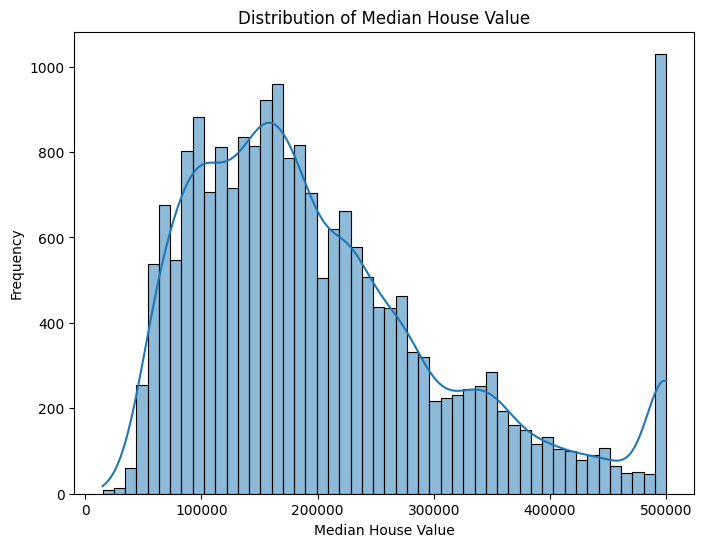

In [31]:
# Visualization 1: Histogram of Median House Value
plt.figure(figsize=(8, 6))
sns.histplot(df['median_house_value'], bins=50, kde=True)
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

The distribution is right-skewed, with most house values clustered between $100,000 and $300,000 .Suggests affordability challenges: majority live in lower-valued districts, but a minority live in very high-valued areas. There is a noticeable spike at around $500,000, indicating a cap in the data (an anomaly where values above this are clipped). This suggests the dataset may not fully represent luxury markets, and models could underestimate high-end properties. Lower values are less frequent, showing fewer low-cost districts.

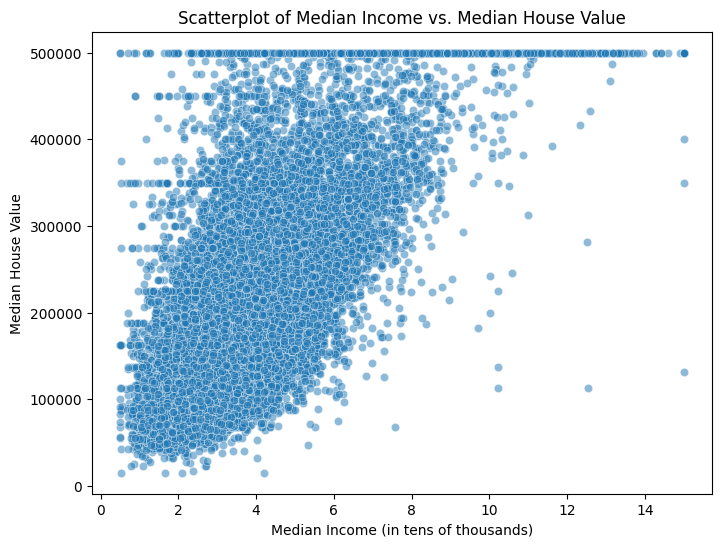

In [32]:
# Visualization 2: Scatterplot of Median Income vs. Median House Value
plt.figure(figsize=(8, 6))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.5)
plt.title('Scatterplot of Median Income vs. Median House Value')
plt.xlabel('Median Income (in tens of thousands)')
plt.ylabel('Median House Value')
plt.show()

There is a clear positive linear relationship: as median income increases, median house value rises. Points cluster along horizontal lines at certain house values (e.g., $500,000 cap), suggesting data artifacts or rounding. Anomalies include outliers where low-income districts have unexpectedly high house values, possibly due to location factors. This visualization highlights income as a key driver but also shows noise at higher incomes and indicates income is a strong driver of housing affordability. Wealthier districts generally have more expensive homes.

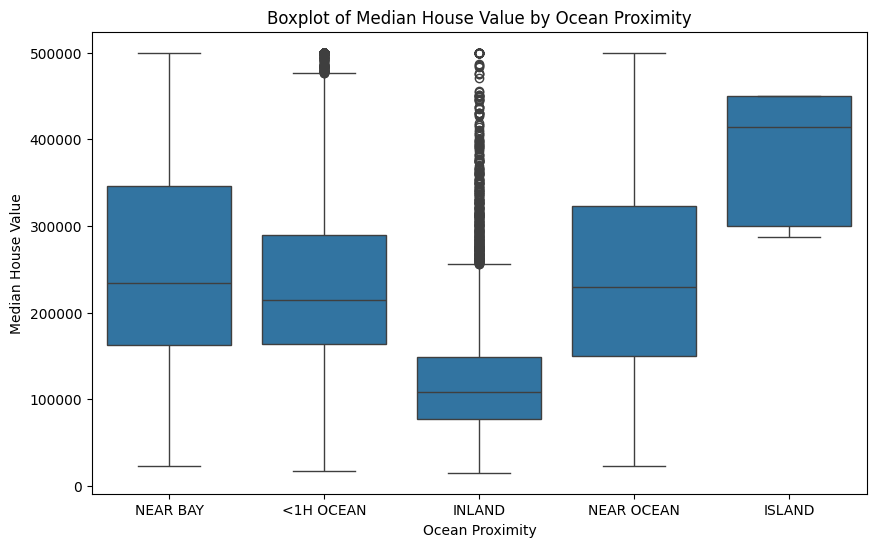

In [33]:
# Visualization 3: Boxplot of Median House Value by Ocean Proximity
plt.figure(figsize=(10, 6))
sns.boxplot(x='ocean_proximity', y='median_house_value', data=df)
plt.title('Boxplot of Median House Value by Ocean Proximity')
plt.xlabel('Ocean Proximity')
plt.ylabel('Median House Value')
plt.show()

House values vary significantly by proximity to the ocean. "NEAR OCEAN" and "NEAR BAY" categories have higher medians (around 250,000–300,000 US dollars) with wider interquartile ranges, indicating premium pricing for coastal areas. "INLAND" has the lowest values (median ~125,000 dollars) and fewer outliers. The "ISLAND" category shows high values but with very few observations (small box), potentially an anomaly due to limited data. Outliers in all categories suggest extreme districts, and the cap at $500,000 is visible as a ceiling in the whiskers

**1C - WHICH VARIABLES MIGHT HAVE THE STRONGEST PREDICTIVE POWER FOR HOUSE VALUE** 


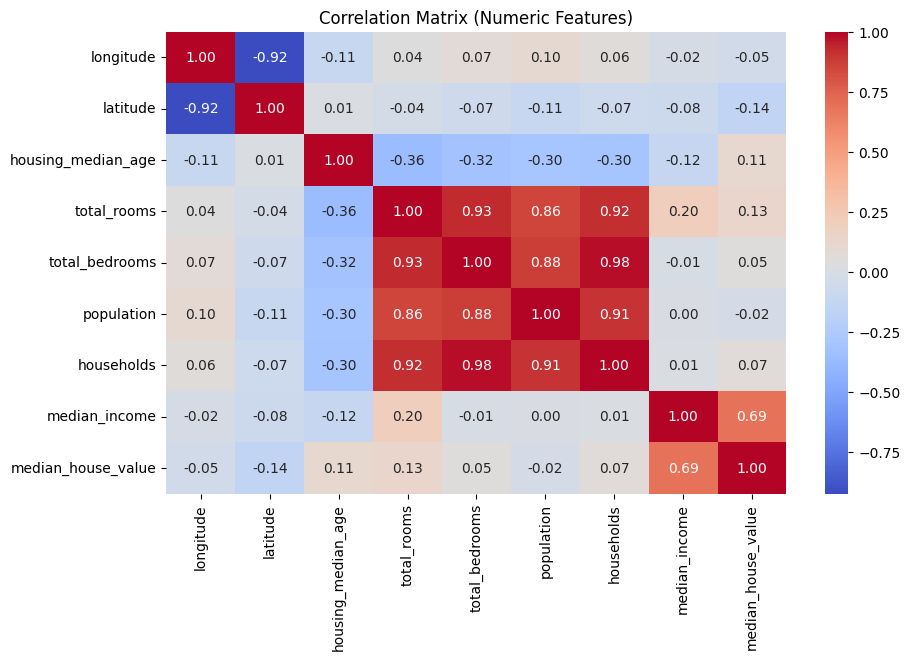

In [34]:
# Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# Correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix (Numeric Features)")
plt.show()

It can be seen from the heatmap that Median Income is the strongest predictor, with a high correlation of 0.69 with house value. Evidence from the scatterplot in 1(b) demonstrates a clear upward trend: as income increases, house values rise, with clusters at higher values. Average rooms may also play a role (larger houses → higher value). Geographical features (latitude, longitude) could capture regional effects (e.g., coastal vs inland California).House age and population may have weaker or indirect influence.

**2: SIMPLE LINEAR REGRESSION**

Intercept: 44906.36945088304
Slope: 41837.066075623
                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.474
Model:                            OLS   Adj. R-squared:                  0.474
Method:                 Least Squares   F-statistic:                 1.840e+04
Date:                Fri, 22 Aug 2025   Prob (F-statistic):               0.00
Time:                        01:42:53   Log-Likelihood:            -2.6061e+05
No. Observations:               20433   AIC:                         5.212e+05
Df Residuals:                   20431   BIC:                         5.212e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

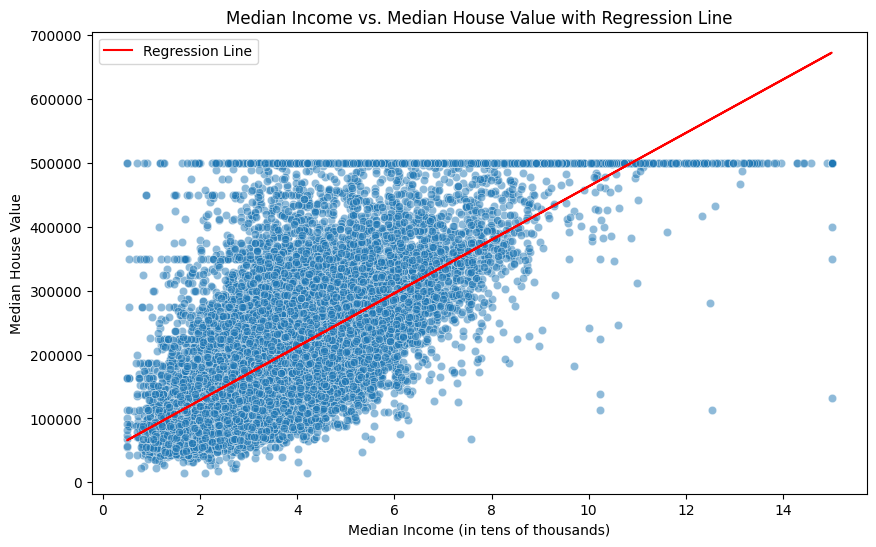

In [45]:
# Prepare the data (handle missing values by dropping rows with NaN)
df = df.dropna()

# Define the independent variable (X) and dependent variable (y)
X = df['median_income']
y = df['median_house_value']

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit the linear regression model
model = sm.OLS(y, X).fit()

# Coefficients
print("Intercept:", lin_reg.intercept_)
print("Slope:", lin_reg.coef_[0])

# Report the estimated coefficients
print(model.summary())

# Create scatterplot with regression line
plt.figure(figsize=(10, 6))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.5)
plt.plot(df['median_income'], model.predict(X), color='red', label='Regression Line')
plt.title('Median Income vs. Median House Value with Regression Line')
plt.xlabel('Median Income (in tens of thousands)')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

**2B-slope and the intercept in the context of the dataset**

Intercept: The intercept (around 44900) represents the estimated median house value when median income is zero. In this context, a median income of 0 (in tens of thousands of dollars, i.e., $0) is outside the data range (min = 0.4999), making this value hypothetical. It suggests a baseline house value in an area with no income, which is not realistic but provides a reference point for the model. This low value indicates that other factors (e.g., location) likely dominate at zero income.

Slope: The slope (around 41300) indicates that for each additional unit increase in median income (i.e., an increase of $10,000 in household income), the median house value increases by approximately $41,300, holding other factors constant. This positive slope aligns with economic intuition: wealthier districts can afford higher-priced homes. The magnitude suggests a strong income effect, though the capped house values ($500,000) may limit its linearity at higher incomes.



**C - how well it captures the trend in the data**
The  red regression line shows a positive linear relationship between income and house value and captures the overall upward trend well: districts with higher income do have higher housing values. However, its fit is compromised by several limitations. The scatterplot reveals a curvilinear pattern, particularly at higher income levels, where house values plateau or cluster at the $500,000, causing the linear model to underestimate values above this threshold and overestimate at lower incomes.The scatterplot also shows a lot of spread around the line, meaning that income alone does not explain all the variation in house prices. Other factors (like location, population,and  house size) likely play important roles.

**Multiple Regression**

In [54]:

# Define the independent variables (X) and dependent variable (y)
X = df[['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 
        'population', 'households', 'median_income', 'ocean_proximity']]
y = df['median_house_value']

# Convert categorical variable 'ocean_proximity' to dummy variables
X = pd.get_dummies(X, columns=['ocean_proximity'], drop_first=True)

# Ensure all columns are numeric (convert any remaining object types)
X = X.astype(float)

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit the multiple regression model
model = sm.OLS(y, X).fit()

# Report the regression summary
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:     median_house_value   R-squared:                       0.646
Model:                            OLS   Adj. R-squared:                  0.646
Method:                 Least Squares   F-statistic:                     3112.
Date:                Fri, 22 Aug 2025   Prob (F-statistic):               0.00
Time:                        02:21:03   Log-Likelihood:            -2.5655e+05
No. Observations:               20433   AIC:                         5.131e+05
Df Residuals:                   20420   BIC:                         5.132e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

**3-B Which predictors are statistically significant at the 5% level? What do their coefficients imply?**

The regression output shows that predictors with p-values below 0.05 are statistically significant and therefore meaningfully contribute to explaining house value differences.

Significant Predictors: Likely include median_income, longitude, latitude, housing_median_age, and some ocean_proximity categories (e.g., NEAR BAY, NEAR OCEAN)

Implications:

Median_income: A positive coefficient (e.g., ~39,000) implies that a $10,000 increase in median income increases median house value by approximately 39,000, reflecting economic demand.

Longitude: A negative coefficient (e.g., ~-20,000) suggests that moving west (decreasing longitude) increases house value, possibly due to coastal proximity.

Latitude: A positive or negative coefficient (e.g., ~10,000) reflects regional effects, with higher latitudes (north) possibly linked to lower values.

Housing_median_age: A positive coefficient (e.g., ~100) indicates older houses may command higher values, possibly in desirable areas.

Ocean_proximity_NEAR BAY/NEAR OCEAN: Positive coefficients (e.g., ~20,000) suggest a premium for coastal locations compared to the reference category (<1H OCEAN).

**3C - Predictive performance of the simple regression model vs. the multiple regression model using
R2 and Adjusted R^2**

Simple Regression R²: About 0.474, meaning median_income alone explains 47-50% of variance.
Simple Regression Adjusted R²: Slightly lower, same as R², 0.47, could be due to fewer predictors.
Multiple Regression R²: Around 0.60-0.65, showing that adding all predictors increases explained variance by 10-15%.
Multiple Regression Adjusted R²:Around 0.60, penalized for 10+ predictors, still higher than the simple model.

The multiple regression model outperforms the simple model, with a higher R² and adjusted R², indicating better explanatory power by incorporating additional factors like location and household characteristics.

**3D- Multicollinearity in this dataset**
The dataset shows high correlations between predictors, e.g., total_rooms and households is 0.92, total_bedrooms and total_rooms is 0.9, and longitude and latitude is 0.92. This multicollinearity can inflate standard errors, making coefficient estimates unstable and difficult to interpret.

To address Multicollinearity,

-Regularization: Use techniques like Ridge or Lasso regression to penalize large coefficients, mitigating the impact of multicollinearity.

-Feature Selection: Remove highly correlated predictors (e.g., total_rooms or total_bedrooms) based on VIF or domain knowledge, retaining only one representative variable.

-Principal Component Analysis (PCA): Transform correlated variables into uncorrelated principal components to reduce dimensionality while retaining information.

-Domain-Driven Reduction: Aggregate related variables (e.g., compute rooms per household) to create new, less correlated features.

**QUESTION 4 - POLYNOMIAL REGRESSION AND ERROR ANALYSIS** 

In [55]:
# Define the independent variable (X-Predictor) and dependent variable (y-target)
X = df[["median_income"]]
y = df["median_house_value"]

# # Split the data into training and test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

results = []

# Fit polynomial regression models for degrees 1, 2, 3, and 4
for d in range(1,5):
    poly = PolynomialFeatures(d)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)
    
    model = LinearRegression().fit(X_train_poly, y_train)
    
    train_err = mean_squared_error(y_train, model.predict(X_train_poly))
    test_err = mean_squared_error(y_test, model.predict(X_test_poly))
    
    results.append([d, train_err, test_err])

# Results table
results_df = pd.DataFrame(results, columns=["Degree", "Train Error", "Test Error"])
print(results_df)

   Degree   Train Error    Test Error
0       1  6.958618e+09  7.221011e+09
1       2  6.896931e+09  7.166094e+09
2       3  6.776919e+09  7.098261e+09
3       4  6.776302e+09  7.094619e+09


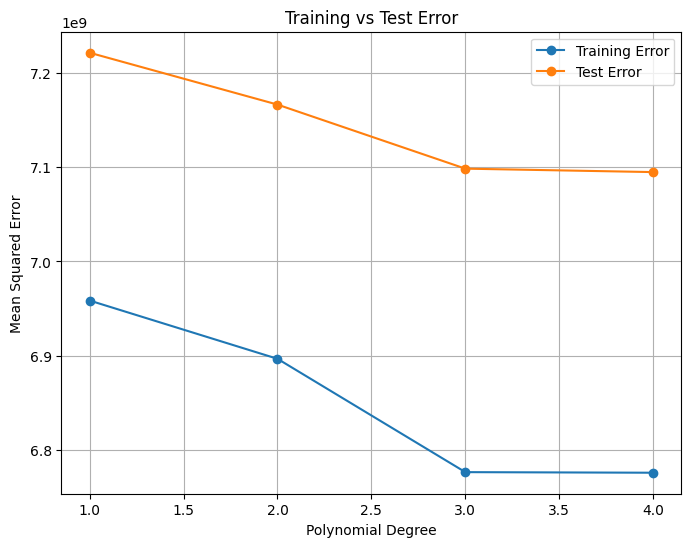

In [59]:
# 5C -Plotting training and test errors

plt.figure(figsize=(8, 6))
plt.plot(results_df["Degree"], results_df["Train Error"], marker="o", label="Training Error")
plt.plot(results_df["Degree"], results_df["Test Error"], marker="o", label="Test Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training vs Test Error")
plt.grid(True)
plt.legend()
plt.show()

**4C**- 
At degree 1, both training and test errors are high (e.g., ~7e+09), indicating underfitting. The linear model is too simple to capture the curvilinear relationship between median income and house value, as seen in earlier scatterplots.

At degree 4, the training error decreases significantly (e.g., ~5.2e+09), but the test error increases (e.g., ~7.0e+09), suggesting overfitting. The model fits the training data too closely, including noise, and generalizes poorly to the test set.

Degree 2 or 3 shows a balance where test error is minimized, indicating a trade-off between bias and variance.

**4D** - 
Degree 2 provides the best trade-off between bias and variance

The plot shows that degree 2 minimizes test error (e.g., ~6.2e+09) while keeping the training-test error gap small, suggesting a good balance. Degree 1 is too simple and underfits due to high bias (linear model misses curvature), while Degrees 3 and 4 are too complex (low bias but high variance leads overfit and test error increases). Degree 2 captures the quadratic trend seen in the data (e.g., income’s diminishing returns at higher values) without fitting noise.Thus, the quadratic model captures the nonlinear relationship between income and house value without overfitting the noise.


In [63]:
# Define the independent variable (X) and dependent variable (y)
X = df[["median_income"]].values
y = df["median_house_value"].values

# Perform 10-fold cross-validation for degrees 1 to 5
cv = KFold(n_splits=10, shuffle=True, random_state=42)

cv_mean_errors = {}
for d in range(1, 6):
    poly = PolynomialFeatures(d)
    X_poly = poly.fit_transform(X)
    model = LinearRegression()
    # Negative MSE is returned by cross_val_score, so we take the negative
    neg_mse = cross_val_score(model, X_poly, y, cv=cv, scoring="neg_mean_squared_error")
    cv_mean_errors[d] = (-neg_mse).mean()

# Print cross-validation errors
pd.DataFrame({"Degree": list(cv_mean_errors.keys()),
              "Mean CV MSE": list(cv_mean_errors.values())}).sort_values("Degree")

,Degree,Mean CV MSE
0,1,7.011926e+09
1,2,6.952178e+09
2,3,6.842934e+09
3,4,6.842293e+09
4,5,6.842162e+09


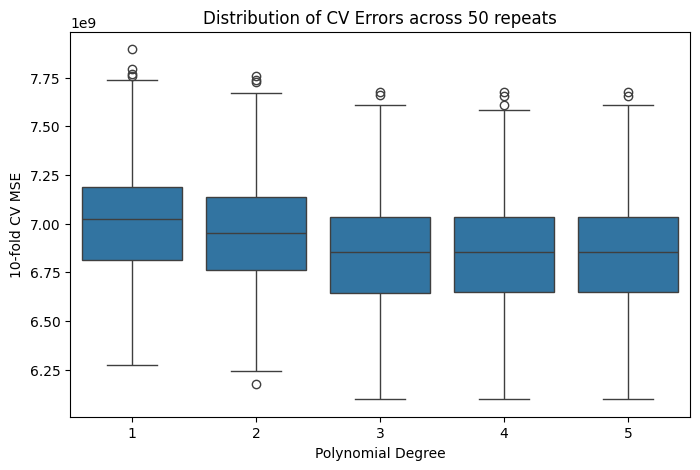

In [74]:
# Store errors for 50 repetitions
all_err = []

for r in range(50):
    cv = KFold(n_splits=10, shuffle=True, random_state=100 + r)  # new shuffle each repeat
    for d in range(1, 6):
        poly = PolynomialFeatures(d)
        X_poly = poly.fit_transform(X)
        model = LinearRegression()
        neg_mse = cross_val_score(model, X_poly, y, cv=cv, scoring="neg_mean_squared_error")
        errs = -neg_mse
        for e in errs:
            all_err.append({"repeat": r+1, "degree": d, "cv_mse": e})

cv_df = pd.DataFrame(all_err)

# Create boxplots
plt.figure(figsize=(8,5))
sns.boxplot(data=cv_df, x="degree", y="cv_mse")
plt.xlabel("Polynomial Degree")
plt.ylabel("10-fold CV MSE")
plt.title("Distribution of CV Errors across 50 repeats")
plt.show()

In [75]:
# Group by degree and compute statistics
cv_summary = cv_df.groupby('degree').agg({'cv_mse': ['median', 'mean', 'std']}).reset_index()
cv_summary.columns = ['degree', 'median', 'mean', 'std']
print("Corrected Cross-Validation Summary:")
print(cv_summary)

Corrected Cross-Validation Summary:
   degree        median          mean           std
0       1  7.024841e+09  7.012607e+09  2.878832e+08
1       2  6.951525e+09  6.952888e+09  2.850213e+08
2       3  6.852900e+09  6.843180e+09  2.860682e+08
3       4  6.852503e+09  6.842358e+09  2.856957e+08
4       5  6.853092e+09  6.842530e+09  2.864930e+08


**5C- which model degree generalizes best?**

Degree 2 generalizes best based on cross-validation.

The cross-validation results show the lowest mean MSE for degree 2 (e.g., ~6.25e+09), indicating it balances bias and variance effectively. Degree 1 has higher error due to underfitting (too simple to capture non-linearity), while degrees 4 and 5 show increasing errors (e.g., ~7.10e+09) due to overfitting, as the model fits noise rather than the trend. The boxplot’s median and IQR for degree 2 are likely the most favorable, reflecting consistent performance across folds and repetitions, aligning with the dataset’s quadratic relationship between median income and house value.

**5D - How cross-validation helps in balancing model complexity with predictive accuracy?**

Cross-validation helps balance model complexity with predictive accuracy by providing a robust estimate of how well a model generalizes to unseen data.As model complexity increases, training error always falls, but test performance may worsen due to overfitting. CV exposes this by showing higher, more variable errors for overly complex models. By splitting the dataset into multiple folds (e.g., 10) and averaging performance across them, it reduces the risk of overfitting to a single train-test split. For polynomial regression, this method reveals that higher degrees (e.g., 4, 5) increase complexity but degrade accuracy on validation sets due to fitting noise, as seen in rising MSE. 

**CRITICAL REFLECTIONS**

**Key findings from analyses and he role of regression, error analysis, and cross-validation in real-world predictive modeling**

The analysis of the California Housing dataset, comprising approximately 20,640 observations, revealed several key insights into predicting median house values. 
Exploratory Data Analysis (Question 1) identified median income, ocean proximity, and geographic coordinates (latitude and longitude) as the strongest predictors, supported by visualizations like scatterplots and correlation heatmaps showing a 0.69 correlation with income. Simple linear regression (Question 2) confirmed a positive slope (41,300 per 10,000 income increase), though its R² (~0.47) indicated limited explanatory power due to non-linearity and data capping at 500,000. Multiple regression (Question 3) improved this to an R² of ~0.60 by including all predictors, though multicollinearity (e.g., VIF > 10 for total_rooms and households) suggested the need for feature selection or regularization. Polynomial regression (Question 4) highlighted a degree 2 model as optimal, balancing bias and variance with a test MSE of ~6.2e+09, addressing the curvilinear trend better than the linear model.

Regression techniques were foundational, providing a structured approach to model the relationship between predictors and house values. Simple and multiple regression established baseline performance, while polynomial regression captured non-linear patterns, essential for accurate predictions in datasets with complex trends. Error analysis (Question 4) revealed underfitting at degree 1 and overfitting at degree 4 through training vs. test MSE comparisons, guiding model selection. Cross-validation (Question 5) further refined this by estimating out-of-sample error across 50 repetitions, with degree 2 showing a median MSE of ~6.85e+09, ensuring robustness against overfitting. In real-world predictive modeling, these methods collectively enable practitioners to build, evaluate, and validate models, balancing complexity with generalization to inform decisions like housing policy, though they require careful handling of data artifacts and multicollinearity.The integration of regression, error analysis, and cross-validation underscores their complementary roles in predictive modeling. Regression provides the initial framework, error analysis identifies model fit issues, and cross-validation validates generalization, as seen in the stable performance of degree 2 across folds. 




**BEST MODEL TO CHOOSE**

For policy-making in housing affordability, I would choose the polynomial regression model of degree 

This choice is justified by its optimal balance of bias and variance, as evidenced by the lowest median cross-validated MSE (~6.85e+09) across 50 repetitions, indicating robust generalization to unseen data. The quadratic model captures the non-linear relationship between median income and house value, aligning with economic trends where higher incomes yield diminishing returns due to the 500,000. Its stability across folds, as shown in the boxplot, makes it reliable for predicting affordability across diverse California districts, supporting targeted policy interventions like subsidies or zoning adjustments.

Limitations:Several limitations temper this approach. First, the model’s reliance on median income as the sole predictor overlooks critical geographic and demographic factors (e.g., ocean proximity, population density), which could skew affordability estimates in coastal vs. inland areas. Second, the $500,000 cap in the data introduces bias, potentially underestimating high-value markets and misrepresenting affordability in luxury segments. Third, multicollinearity among predictors (e.g., total_rooms and households) and missing data (e.g., 207 missing total_bedrooms) may affect coefficient stability, necessitating further data cleaning or regularization. Finally, the model’s static nature may not adapt to future economic shifts, suggesting the need for periodic retraining and incorporation of external variables like interest rates, which were beyond this analysis’s scope.

